# Error analysis plots

### This notebook is designed to help in aiding the analysis process of the final model and give more insight into how the model makes its predictions.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from transformers import CamembertForSequenceClassification, CamembertTokenizer
import torch
from torch.utils.data import DataLoader, TensorDataset

2025-04-10 20:10:23.067220: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-04-10 20:10:23.081940: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1744315823.097056      53 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1744315823.101732      53 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1744315823.115475      53 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

In [5]:
# Load the saved model and tokenizer
model = CamembertForSequenceClassification.from_pretrained('../Task 5/camembert_model_6')
tokenizer = CamembertTokenizer.from_pretrained('camembert-base')  # Use the tokenizer that was used during training

# Ensure the model is in evaluation mode
model.eval()

CamembertForSequenceClassification(
  (roberta): CamembertModel(
    (embeddings): CamembertEmbeddings(
      (word_embeddings): Embedding(32005, 768, padding_idx=1)
      (position_embeddings): Embedding(514, 768, padding_idx=1)
      (token_type_embeddings): Embedding(1, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): CamembertEncoder(
      (layer): ModuleList(
        (0-11): 12 x CamembertLayer(
          (attention): CamembertAttention(
            (self): CamembertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): CamembertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias

In [7]:
# Load the training dataset
features = "../Task 4/final_dataset.csv"
df= pd.read_csv(features)

In [8]:
# Encoding sentences function
def encode_sentences(sentences):
    return tokenizer(sentences.tolist(), padding=True, truncation=True, max_length=128, return_tensors='pt')

## a. Predictions

In [15]:
from sklearn.preprocessing import LabelEncoder
df_test = pd.read_csv("../Task 5/test_data/transformers_test_dataset.csv")

# Encode labels
label_encoder_camembert = LabelEncoder()
df["emotion_label"] = label_encoder_camembert.fit_transform(df["Emotion"])
df_test = df_test[['Sentence', 'Emotion']]
df_test["emotion_label"] = label_encoder_camembert.transform(df_test["Emotion"])

# Tokenize the sentences in the test data
encoded_test_inputs = encode_sentences(df_test['Sentence'])
test_input_ids = encoded_test_inputs["input_ids"]
test_attention_mask = encoded_test_inputs["attention_mask"]

# Convert to torch tensors
test_inputs = torch.tensor(test_input_ids).clone().detach()
test_attn = torch.tensor(test_attention_mask).clone().detach()
test_labels = torch.tensor(df_test['emotion_label'].values)

# Create a DataLoader
test_data = TensorDataset(test_inputs, test_attn, test_labels)
test_dataloader = DataLoader(test_data, batch_size=16)

# Set model to evaluation mode
model.eval()

# To store predictions, true labels, and track the loss
predicted_labels_list = []
true_labels_list = []
total_test_loss = 0  
correct_predictions = 0  
total_predictions = 0  

# Set the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

with torch.no_grad():  # Disable gradient calculation to save memory
    for batch in test_dataloader:
        input_ids, attention_mask, labels = batch
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        # Get model outputs
        outputs = model(input_ids, attention_mask=attention_mask, labels=labels)
        logits = outputs.logits
        loss = outputs.loss  # Extract the loss from the model output

        # Accumulate the loss
        total_test_loss += loss.item()

        # Get predicted labels
        predictions = torch.argmax(logits, dim=-1)

        # Store predictions and true labels
        predicted_labels_list.extend(predictions.cpu().numpy())
        true_labels_list.extend(labels.cpu().numpy())

        # Track the number of correct predictions
        correct_predictions += (predictions == labels).sum().item()
        total_predictions += labels.size(0)

/tmp/ipykernel_53/723753302.py:16: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  test_inputs = torch.tensor(test_input_ids).clone().detach()
/tmp/ipykernel_53/723753302.py:17: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  test_attn = torch.tensor(test_attention_mask).clone().detach()


## b. Confusion Matrix

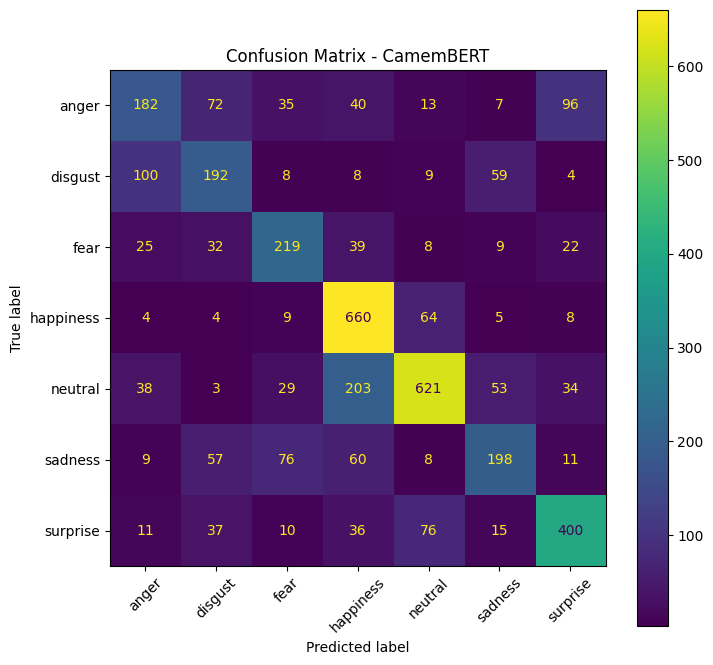

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Get label names back from the label encoder
label_names = label_encoder_camembert.classes_

# Create confusion matrix
cm = confusion_matrix(true_labels_list, predicted_labels_list)

# Display it
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, xticks_rotation=45)
plt.title("Confusion Matrix - CamemBERT")
plt.show()

### Common misclassifications

In [40]:
import numpy as np

confused_pairs = []
for i in range(len(cm)):
    for j in range(len(cm)):
        if i != j and cm[i, j] > 0:
            confused_pairs.append((label_names[i], label_names[j], cm[i, j]))

# Sort by frequency
confused_pairs.sort(key=lambda x: x[2], reverse=True)

print("Most confused class pairs:")
for true_class, predicted_class, count in confused_pairs[:5]:
    print(f"{true_class} → {predicted_class}: {count} times")

Most confused class pairs:
neutral → happiness: 203 times
disgust → anger: 100 times
anger → surprise: 96 times
sadness → fear: 76 times
surprise → neutral: 76 times


## c. Precision, Recall, F1 Score

### Overall metrics

In [17]:
# Convert lists to numpy arrays for metric calculations
predicted_labels = np.array(predicted_labels_list)
true_labels = np.array(true_labels_list)

# Calculate the average test loss
avg_test_loss = total_test_loss / len(test_dataloader)

# Calculate accuracy
accuracy = correct_predictions / total_predictions

# Print the results
print(f"Test Loss: {avg_test_loss:.4f}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")

# Compute Precision, Recall, F1 Score
from sklearn.metrics import precision_recall_fscore_support
precision, recall, f1, _ = precision_recall_fscore_support(true_labels, predicted_labels, average='weighted')

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

Test Loss: 1.8041
Test Accuracy: 63.09%
Precision: 0.6353
Recall: 0.6309
F1-Score: 0.6264


### Class metrics

In [42]:
from sklearn.metrics import precision_recall_fscore_support

# Compute Precision, Recall, F1 Score
precision, recall, f1, _ = precision_recall_fscore_support(true_labels, predicted_labels, average=None)

# Print performance metrics
for idx, emotion in enumerate(label_encoder_camembert.classes_):
    print(f"{emotion} - Precision: {precision[idx]:.4f}, Recall: {recall[idx]:.4f}, F1: {f1[idx]:.4f}")

anger - Precision: 0.4932, Recall: 0.4090, F1: 0.4472
disgust - Precision: 0.4836, Recall: 0.5053, F1: 0.4942
fear - Precision: 0.5674, Recall: 0.6186, F1: 0.5919
happiness - Precision: 0.6310, Recall: 0.8753, F1: 0.7333
neutral - Precision: 0.7772, Recall: 0.6330, F1: 0.6978
sadness - Precision: 0.5723, Recall: 0.4726, F1: 0.5176
surprise - Precision: 0.6957, Recall: 0.6838, F1: 0.6897


## d. Inspect Missclassified Examples

In [18]:
test_texts = df_test["Sentence"].tolist()

# Rebuild misclassified list with label names
misclassified = []

for input_text, pred, true in zip(test_texts, predicted_labels, true_labels):
    if pred != true:
        misclassified.append({
            "text": input_text,
            "predicted": label_encoder_camembert.inverse_transform([pred])[0],
            "true": label_encoder_camembert.inverse_transform([true])[0]
        })

# Print a few misclassified examples with readable labels
for ex in misclassified[:10]:
    print(f"Text: {ex['text']}\nPredicted: {ex['predicted']}, True: {ex['true']}\n")

Text: Oui, oui, oui.
Predicted: fear, True: happiness

Text: C'est bon.
Predicted: neutral, True: happiness

Text: C'est une blague, pardon.
Predicted: happiness, True: fear

Text: Ah, mais non, désolé, c'est beaucoup trop trop chéri.
Predicted: fear, True: disgust

Text: Mais Julien, il freine, il freine, il freine.
Predicted: neutral, True: anger

Text: parce que je n'ai pas envie d'embrasser Pagas.
Predicted: neutral, True: anger

Text: Ça marche, ça marche, ça ne marche pas, tant pis.
Predicted: happiness, True: neutral

Text: Attendez, attendez.
Predicted: neutral, True: surprise

Text: J'ai oublié.
Predicted: anger, True: neutral

Text: Je me mêle de ce qu'ils ne me regardent pas.
Predicted: sadness, True: anger



### Attention maps

Explaining misclassified anger example: #1

Text: C'est la goutte d'eau qui fait déborder le vase !
Predicted Label: disgust
True Label: anger


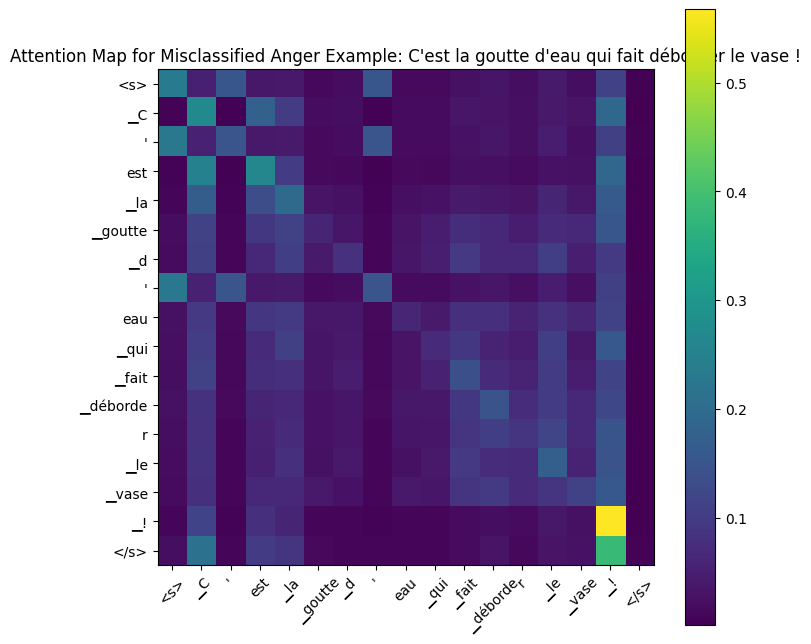



Explaining misclassified anger example: #2

Text: Mais t'es sérieux là ?!
Predicted Label: surprise
True Label: anger


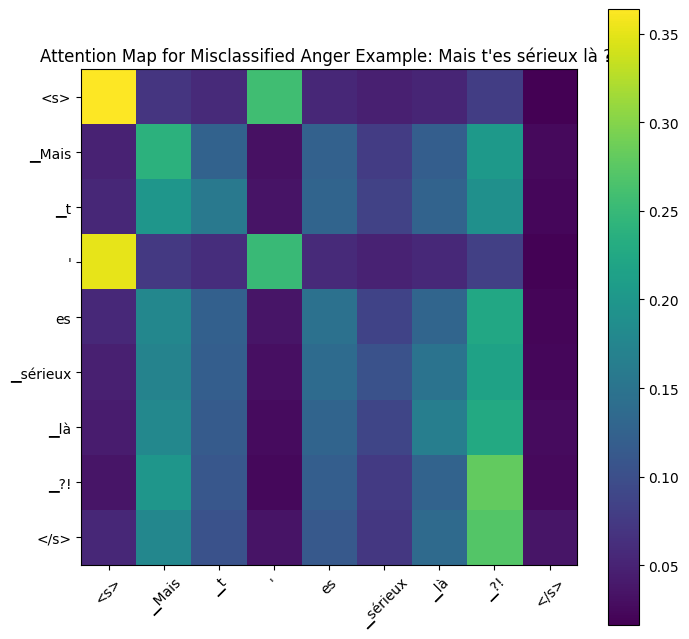



Explaining misclassified anger example: #3

Text: Arrête ton cinéma, je vois clair dans ton jeu !
Predicted Label: disgust
True Label: anger


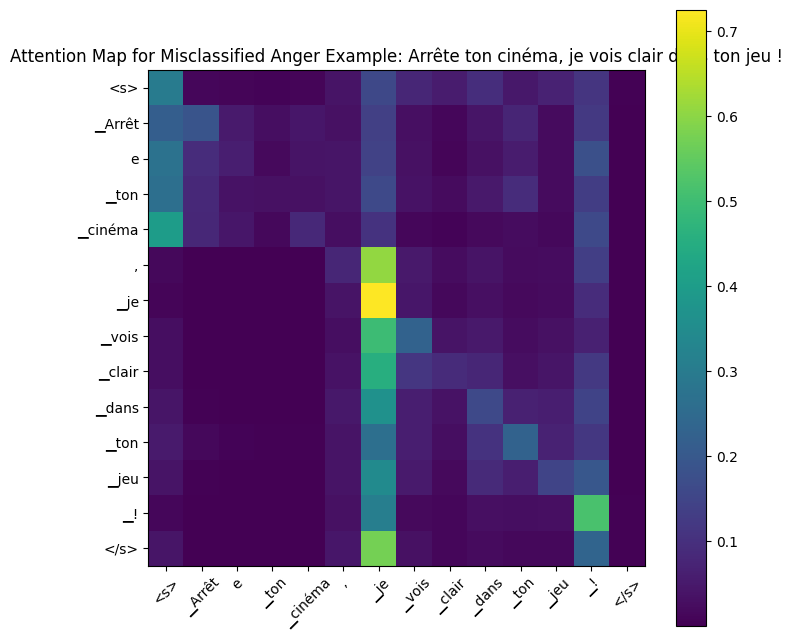



Explaining misclassified anger example: #4

Text: Tu crois que je suis stupide ou quoi ?
Predicted Label: surprise
True Label: anger


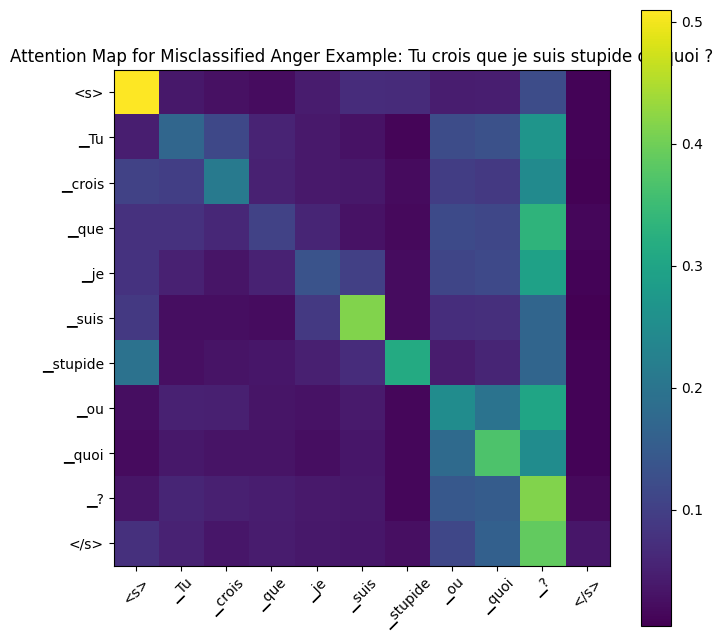



Explaining misclassified anger example: #5

Text: Le mec, il en fait beaucoup avec Julie.
Predicted Label: happiness
True Label: anger


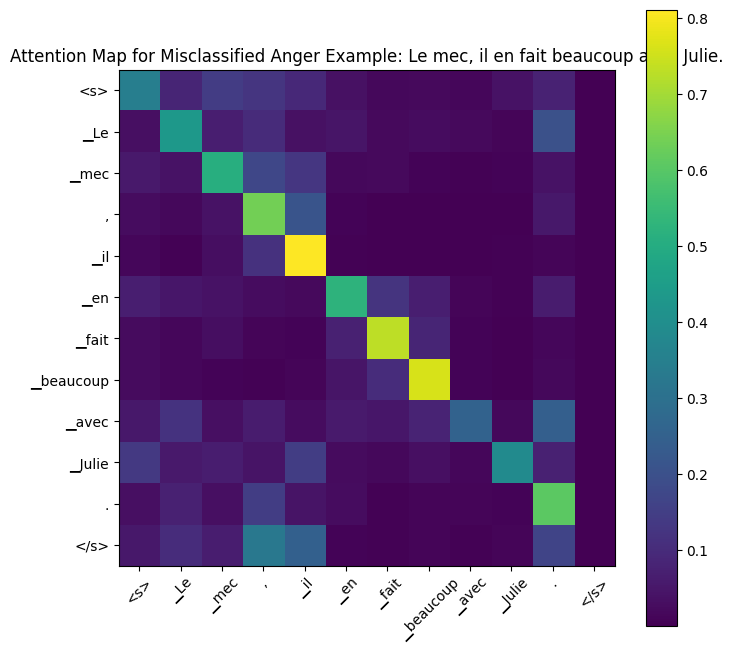



Explaining misclassified anger example: #6

Text: C'est la goutte d'eau qui fait déborder le vase !
Predicted Label: disgust
True Label: anger


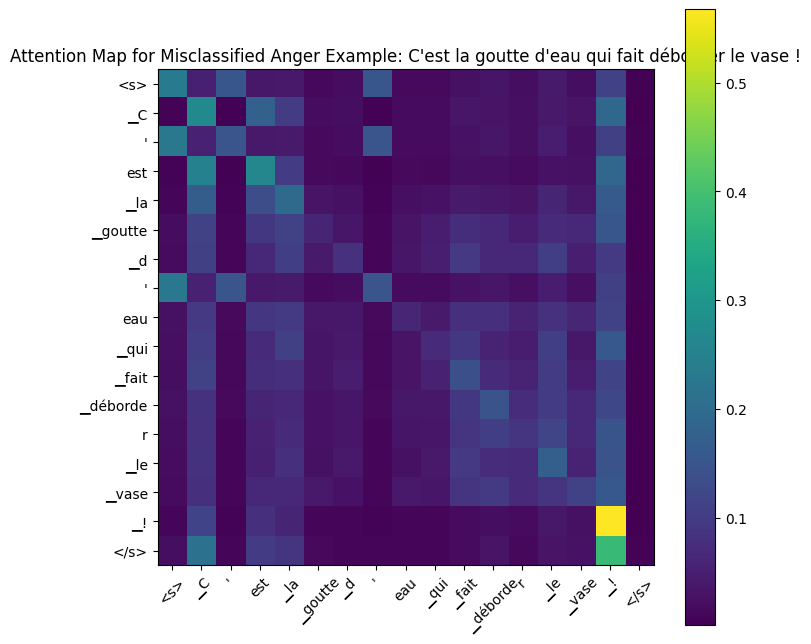



Explaining misclassified anger example: #7

Text: C'est la goutte d'eau qui fait déborder le vase !
Predicted Label: disgust
True Label: anger


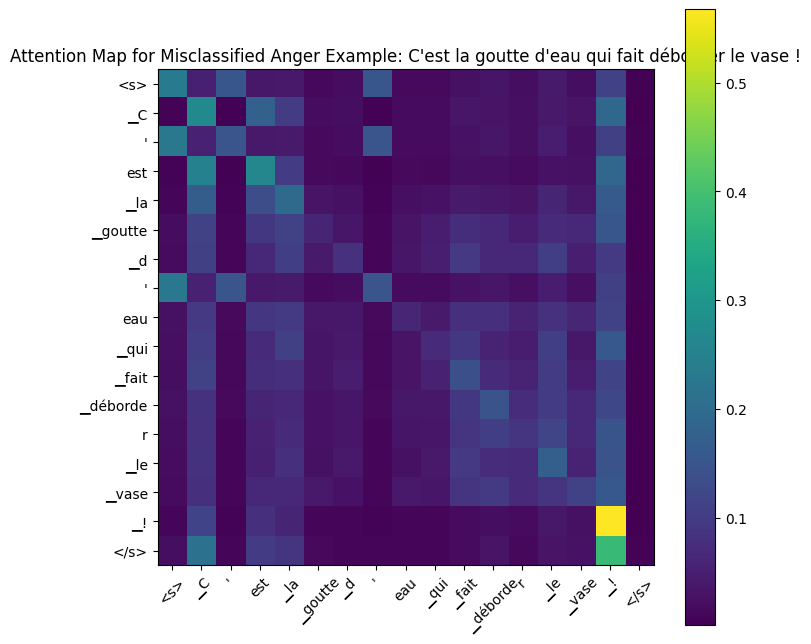



Explaining misclassified anger example: #8

Text: Tu m'as menti depuis le début !
Predicted Label: surprise
True Label: anger


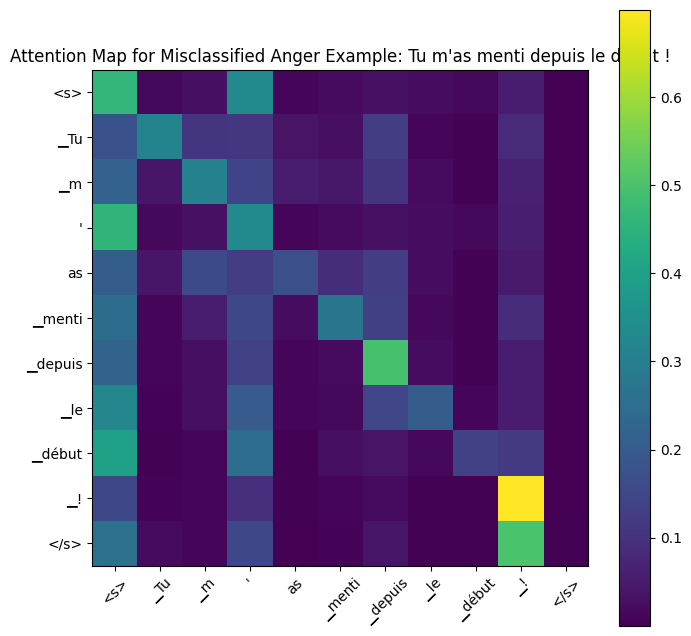



Explaining misclassified anger example: #9

Text: Mais t'es sérieux là ?!
Predicted Label: surprise
True Label: anger


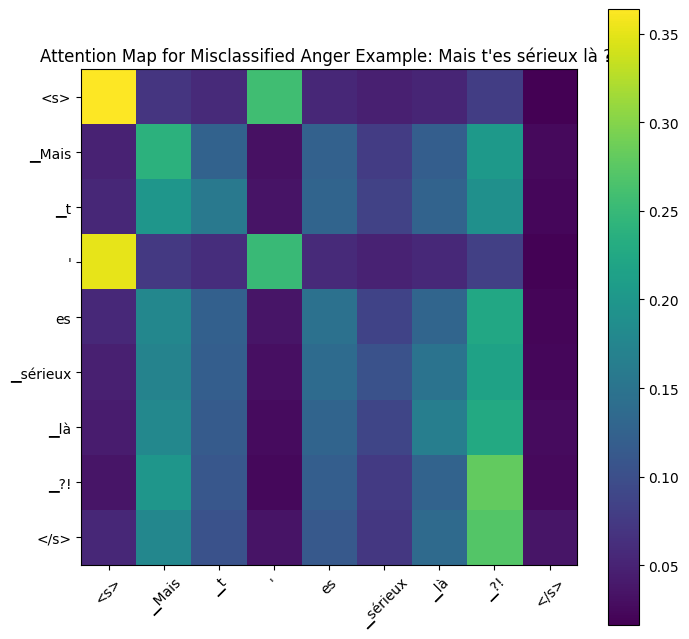



Explaining misclassified anger example: #10

Text: Tu crois que je suis stupide ou quoi ?
Predicted Label: surprise
True Label: anger


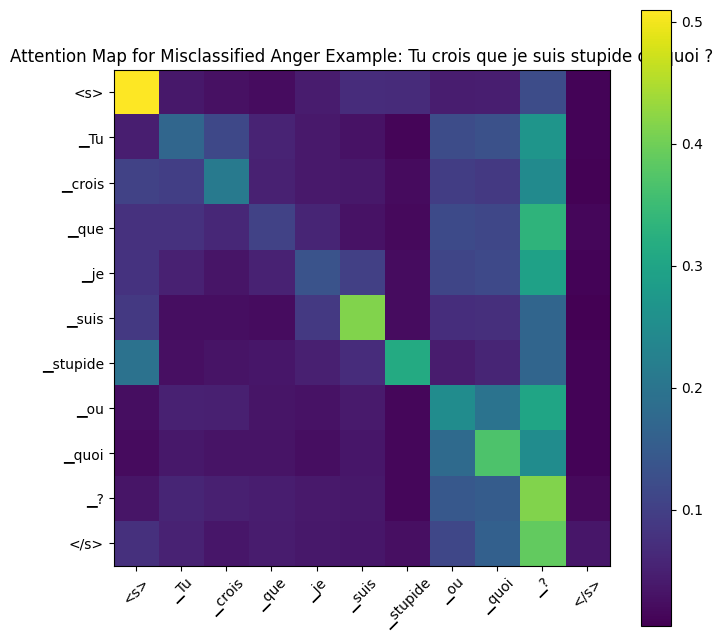

In [63]:
import random
import torch
from transformers import CamembertTokenizer, CamembertForSequenceClassification
import matplotlib.pyplot as plt

# Load model and tokenizer
model = CamembertForSequenceClassification.from_pretrained('../Task 5/camembert_model_6', output_attentions=True)
tokenizer = CamembertTokenizer.from_pretrained('camembert-base')

# Define a function to predict using the model (you might not need this for attention visualization alone)
def predict_fn(texts):
    # Tokenize the input texts
    inputs = tokenizer(texts, return_tensors='pt', padding=True, truncation=True, max_length=512)

    # Move the input tensors to the appropriate device (CPU or GPU)
    inputs = {key: val.to(model.device) for key, val in inputs.items()}

    # Make predictions
    with torch.no_grad():
        outputs = model(**inputs)

    # Get the predicted class probabilities
    probs = torch.nn.functional.softmax(outputs.logits, dim=-1)

    # Return the probabilities for each class
    return probs.cpu().numpy()

# Filter for misclassified examples where the true label is "anger"
anger_misclassified = [ex for ex in misclassified if ex['true'] == 'anger']

# Randomly select up to 10 misclassified "anger" examples
num_examples_to_visualize = min(len(anger_misclassified), 10)
random_anger_misclassified = random.sample(anger_misclassified, num_examples_to_visualize)

ex_count = 1
# Iterate over the randomly selected misclassified "anger" examples and visualize attention
for ex in random_anger_misclassified:
    print(f"Explaining misclassified anger example: #{ex_count}")
    print(f"\nText: {ex['text']}")

    # Also print the predicted label and true label
    print(f"Predicted Label: {ex['predicted']}")
    print(f"True Label: {ex['true']}")

    # Tokenize the text and get the attention weights
    inputs = tokenizer(ex['text'], return_tensors='pt', padding=True, truncation=True, max_length=512)

    # Ensure the model is in evaluation mode
    model.eval()

    with torch.no_grad():
        outputs = model(**inputs)
        attentions = outputs.attentions  # All layers' attentions

    # Choose the attention from the last layer
    last_layer_attention = attentions[-1]  # Shape: [batch_size, num_heads, seq_len, seq_len]

    # Get the attention map of the first head in the last layer
    attention_map = last_layer_attention[0, 0].cpu().numpy()  # First token in the batch

    # Get the tokens
    tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
    ex_count += 1
    # Plot the attention map
    plt.figure(figsize=(8, 8))
    plt.imshow(attention_map, cmap='viridis', interpolation='nearest')
    plt.xticks(range(len(tokens)), tokens, rotation=45)
    plt.yticks(range(len(tokens)), tokens)
    plt.colorbar()
    plt.title(f"Attention Map for Misclassified Anger Example: {ex['text']}")
    plt.show()

    print("\n" + "="*50 + "\n")

### Translations for attention map sentences

1. C'est la goutte d'eau qui fait déborder le vase ! = **This is the last straw!**

2. Mais t'es sérieux là ?! = **Are you serious right now?!**

3. Arrête ton cinéma, je vois clair dans ton jeu ! = **Stop playing games, I see through your act!**

4. Tu crois que je suis stupide ou quoi ? = **Do you think I'm stupid or what?**

5. Le mec, il en fait beaucoup avec Julie. = **The guy is overdoing it with Julie.**

6. C'est la goutte d'eau qui fait déborder le vase ! = **This is the last straw!**

7. C'est la goutte d'eau qui fait déborder le vase ! = **This is the last straw!**

8. Tu m'as menti depuis le début ! = **You lied to me from the start!**

9. Mais t'es sérieux là ?! = **Are you serious right now?!**

10. Tu crois que je suis stupide ou quoi ? = **Do you think I'm stupid or what?**

### LIME analysis

In [27]:
import lime
import lime.lime_text
from sklearn.pipeline import make_pipeline
from transformers import CamembertForSequenceClassification, CamembertTokenizer
import torch
import random

# Define a prediction function for LIME
def predict_fn(texts):
    # Tokenize the input texts
    inputs = tokenizer(texts, return_tensors='pt', padding=True, truncation=True, max_length=512)
    
    # Move the input tensors to the appropriate device (CPU or GPU)
    inputs = {key: val.to(model.device) for key, val in inputs.items()}
    
    # Make predictions
    with torch.no_grad():
        outputs = model(**inputs)
    
    # Get the predicted class probabilities
    probs = torch.nn.functional.softmax(outputs.logits, dim=-1)
    
    # Return the probabilities for each class
    return probs.cpu().numpy()

# Create the LIME Text Explainer
explainer = lime.lime_text.LimeTextExplainer(class_names=label_encoder_camembert.classes_)

# Randomly select 10 misclassified examples
random_misclassified = random.sample(misclassified, 10)

# Counter for example number
example_count = 1

# Iterate over the randomly selected misclassified examples and apply LIME
for ex in random_misclassified:
    print(f"Explaining misclassified example #{example_count}:")
    print(f"Text: {ex['text']}")
    
    # Use LIME to explain the prediction
    explanation = explainer.explain_instance(ex['text'], predict_fn, num_features=10)
    
    # Show the explanation for this example
    explanation.show_in_notebook()
    
    # Also print the predicted label and true label
    print(f"Predicted Label: {ex['predicted']}")
    print(f"True Label: {ex['true']}")
    
    # Alternatively, print the most important features
    print("Most important features:")
    for feature, weight in explanation.as_list():
        print(f"{feature}: {weight}")
    
    print("\n" + "="*50 + "\n")
    
    # Increment the example count
    example_count += 1

Explaining misclassified example #1:
Text: Je me sens tellement seul ici.


Predicted Label: fear
True Label: sadness
Most important features:
seul: -0.014250994134539178
ici: -0.012592686204021966
Je: 0.006029350354830663
sens: -0.00425592887656456
tellement: -0.0032457410720761514
me: 0.00012924266709814545


Explaining misclassified example #2:
Text: Je suis hors de moi !


Predicted Label: fear
True Label: anger
Most important features:
hors: 0.007736288363836542
de: 0.007541619626748384
suis: 0.006146107306251742
moi: -0.005143369786588894
Je: -0.00041056253993173144


Explaining misclassified example #3:
Text: Allez, Kevin !


Predicted Label: happiness
True Label: neutral
Most important features:
Kevin: -0.0004097452365539737
Allez: 0.0002649303609393168


Explaining misclassified example #4:
Text: Je suis dégoûté, je ne veux plus entendre parler de toi.


Predicted Label: sadness
True Label: disgust
Most important features:
veux: -0.2369907511519356
dégoûté: 0.2258532861464428
plus: 0.14473656670961296
Je: 0.09649017439428943
parler: -0.08566184164296975
je: 0.06795282891871825
entendre: 0.043103223446031146
toi: -0.01881063294257898
suis: 0.01325772600582227
ne: -0.008020008533102892


Explaining misclassified example #5:
Text: Qu'est-ce qui se passe bordel ?


...

Predicted Label: happiness
True Label: neutral
Most important features:
fait: -0.05304035955711932
me: 0.038098265040632386
ni: 0.028005975958655227
froid: 0.013490092650114627
chaud: -0.007546769295512125
ne: 0.002596634612346254
Ça: 0.001605946452321263


Explaining misclassified example #7:
Text: Tu vas voir ce que tu vas voir !


Predicted Label: happiness
True Label: anger
Most important features:
Tu: -0.036608086885485974
que: -0.021038142439808217
voir: 0.02034166726582716
vas: 0.017359061383772956
tu: 0.007113702261282226
ce: 0.001696035672132185


Explaining misclassified example #8:
Text: J’ai un mauvais pressentiment sur tout ça...


Predicted Label: disgust
True Label: fear
Most important features:
pressentiment: 0.6423462437070099
mauvais: 0.363563973353031
sur: -0.0825002201083127
ai: 0.07607602143558344
tout: 0.05110499616491383
un: -0.050889621633173045
J: 0.04271738966468971
ça: -0.019883724457630085


Explaining misclassified example #9:
Text: J'ai la trouille...


Predicted Label: happiness
True Label: fear
Most important features:
J: -0.015439807001114724
ai: 0.015369986823380416
la: 0.01313910020892041
trouille: 0.007658335360729674


Explaining misclassified example #10:
Text: Bon, on fait quoi maintenant ?


Predicted Label: happiness
True Label: neutral
Most important features:
Bon: -0.0016337741215021113
on: -0.0014852050015690184
quoi: -0.0007246505089839142
maintenant: 0.00042063257303176754
fait: 0.0002929872755091456




### Translations for the LIME sentences.

1. Je me sens tellement seul ici. = **I feel so alone here.**

2. Je suis hors de moi ! = **I am beside myself!**

3. Allez, Kevin ! = **Come on, Kevin!**

4. Je suis dégoûté, je ne veux plus entendre parler de toi. = **I'm disgusted, I don't want to hear about you anymore.**

5. Qu'est-ce qui se passe bordel ? = **What's going on, damn it?**

6. Ça ne me fait ni chaud ni froid. = **It doesn't matter to me either way.**

7. Tu vas voir ce que tu vas voir ! = **You'll see what you're going to see!**

8. J’ai un mauvais pressentiment sur tout ça... = **I have a bad feeling about all this...**

9. J'ai la trouille... = **I'm scared...**

10. Bon, on fait quoi maintenant ? = **So, what do we do now?**

## e. Checking for words that might cause errors (negations, sarcasm, emotion cues, etc.)

In [45]:
from collections import Counter
import re

# Compile lists of misclassified tokens
error_tokens = []

for ex in misclassified:
    tokens = re.findall(r'\b\w+\b', ex['text'].lower())
    error_tokens.extend(tokens)

# Most common tokens in misclassified examples
common_error_tokens = Counter(error_tokens).most_common(30)

print("Top words in misclassified examples:")
for word, freq in common_error_tokens:
    print(f"{word}: {freq}")

Top words in misclassified examples:
je: 549
est: 347
ça: 270
suis: 251
ce: 240
que: 225
c: 223
tu: 218
de: 200
on: 179
j: 172
fait: 168
qui: 163
me: 162
ai: 160
le: 160
pas: 156
tout: 152
ne: 133
quoi: 107
un: 102
à: 99
la: 99
bien: 97
et: 94
se: 90
verra: 85
passe: 78
ni: 76
t: 75


## f. Sentence Length 

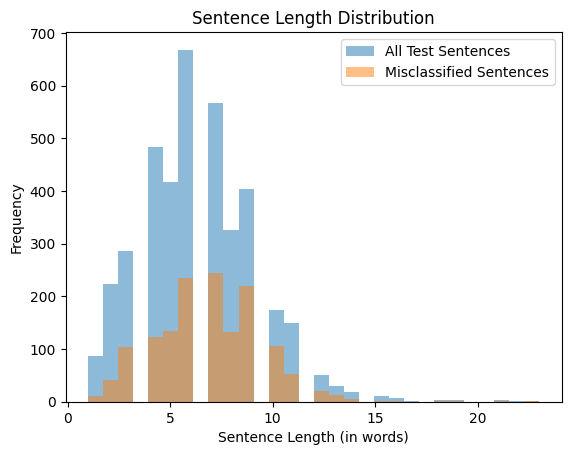

In [24]:
import matplotlib.pyplot as plt

all_lengths = [len(t.split()) for t in test_texts]
error_lengths = [len(ex['text'].split()) for ex in misclassified]

plt.hist(all_lengths, bins=30, alpha=0.5, label='All Test Sentences')
plt.hist(error_lengths, bins=30, alpha=0.5, label='Misclassified Sentences')
plt.xlabel('Sentence Length (in words)')
plt.ylabel('Frequency')
plt.title('Sentence Length Distribution')
plt.legend()
plt.show()

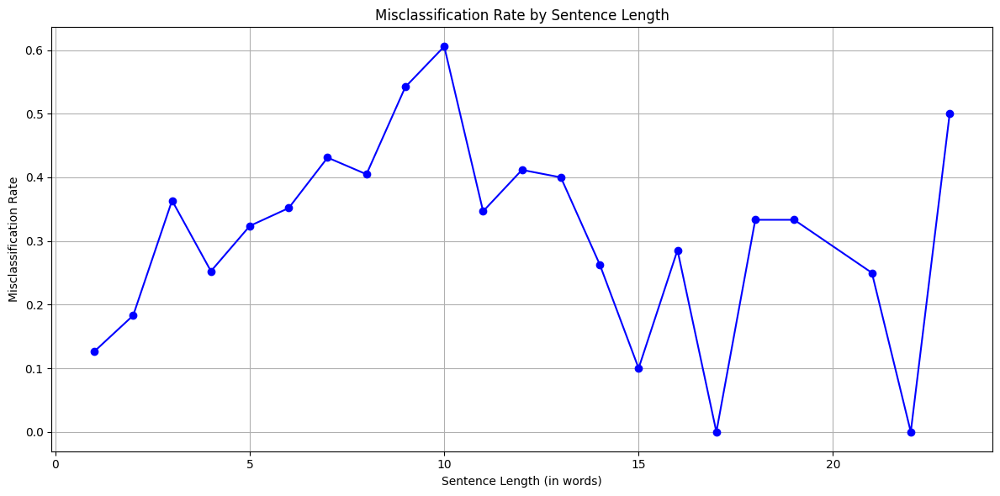

In [55]:
# Add sentence length to the dataframe
df_test["sentence_length"] = df_test["Sentence"].apply(lambda x: len(x.split()))

# Calculate misclassification by sentence length
df_test["misclassified"] = df_test["predicted_label"] != df_test["emotion_label"]
misclass_by_length = df_test.groupby("sentence_length")["misclassified"].mean()

# Plot
plt.figure(figsize=(12, 6))
plt.plot(misclass_by_length.index, misclass_by_length.values, color='blue', marker='o')
plt.title("Misclassification Rate by Sentence Length")
plt.xlabel("Sentence Length (in words)")
plt.ylabel("Misclassification Rate")
plt.grid(True)
plt.tight_layout()
plt.show()

## g. Class Bias

/tmp/ipykernel_53/128356109.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_53/128356109.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


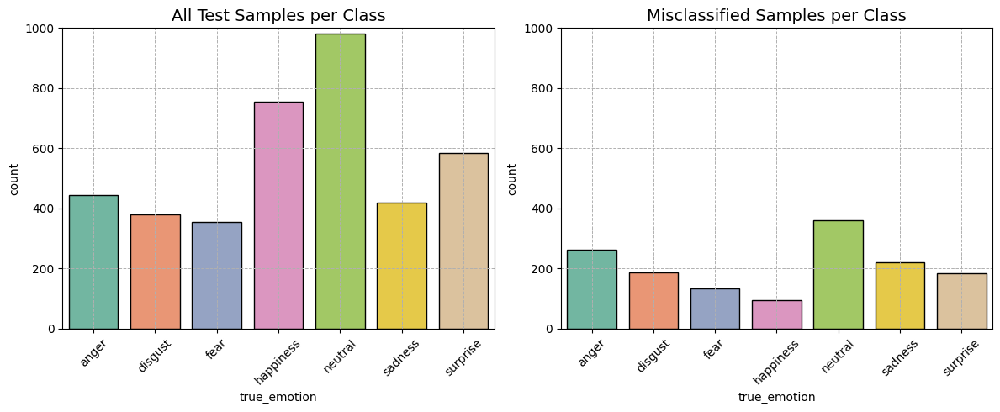

In [50]:
# Add predicted labels to df_test
df_test["predicted_label"] = predicted_labels_list

# Now create readable emotion names for predicted and true labels
df_test["true_emotion"] = label_encoder_camembert.inverse_transform(df_test["emotion_label"])
df_test["predicted_emotion"] = label_encoder_camembert.inverse_transform(df_test["predicted_label"])

# Mark misclassified samples
df_test["misclassified"] = df_test["emotion_label"] != df_test["predicted_label"]

# Grab only as many colors as needed
emotion_classes = sorted(df_test["true_emotion"].unique())
num_classes = len(emotion_classes)
colors = sns.color_palette("Set2", n_colors=num_classes)

# Create a dictionary to map emotion classes to colors
emotion_color_map = {emotion: color for emotion, color in zip(emotion_classes, colors)}

plt.figure(figsize=(12, 5))

# All test samples per class
plt.subplot(1, 2, 1)
sns.countplot(
    data=df_test,
    x="true_emotion",
    order=emotion_classes,
    palette=emotion_color_map,  # Set colors explicitly
    edgecolor='black',
    linewidth=1,
    legend=False  # Hide duplicated legend
)
plt.title("All Test Samples per Class", fontsize=14)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', linewidth=0.7)
plt.ylim(0, 1000)

# Misclassified samples per class
plt.subplot(1, 2, 2)
sns.countplot(
    data=df_test[df_test["misclassified"]],
    x="true_emotion",
    order=emotion_classes,
    palette=emotion_color_map,  # Set colors explicitly
    edgecolor='black',
    linewidth=1,
    legend=False  # Hide duplicated legend
)
plt.title("Misclassified Samples per Class", fontsize=14)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', linewidth=0.7)
plt.ylim(0, 1000)
plt.tight_layout()
plt.show()

In [51]:
df_test['Emotion'].value_counts()

Emotion
neutral      981
happiness    754
surprise     585
anger        445
sadness      419
disgust      380
fear         354
Name: count, dtype: int64

/tmp/ipykernel_53/3721529198.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


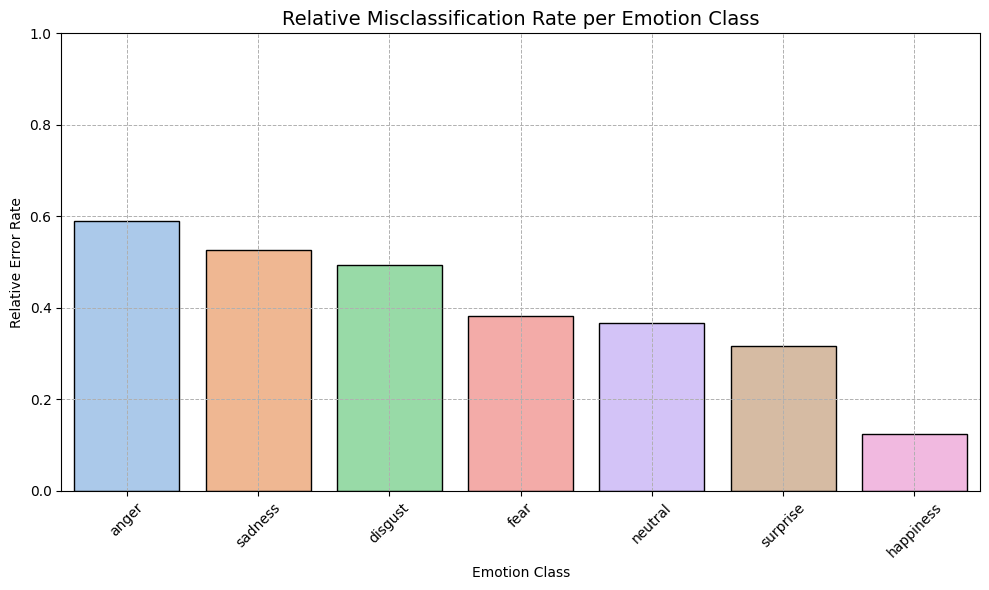

In [53]:
# import matplotlib.pyplot as plt
import seaborn as sns

# Count total and misclassified samples per class
total_counts = df_test["true_emotion"].value_counts().sort_index()
misclassified_counts = df_test[df_test["misclassified"]]["true_emotion"].value_counts().sort_index()

# Ensure alignment
relative_errors = (misclassified_counts / total_counts).fillna(0)

# Sort by error rate for better visualization
relative_errors = relative_errors.sort_values(ascending=False)

# Set color palette
colors = sns.color_palette("pastel", n_colors=len(relative_errors))

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(
    x=relative_errors.index,
    y=relative_errors.values,
    palette=colors,
    edgecolor='black',
    linewidth=1
)
plt.ylabel("Relative Error Rate")
plt.xlabel("Emotion Class")
plt.title("Relative Misclassification Rate per Emotion Class", fontsize=14)
plt.xticks(rotation=45)
plt.ylim(0, 1) 
plt.tight_layout()
plt.grid(True, linestyle='--', linewidth=0.7)
plt.show()

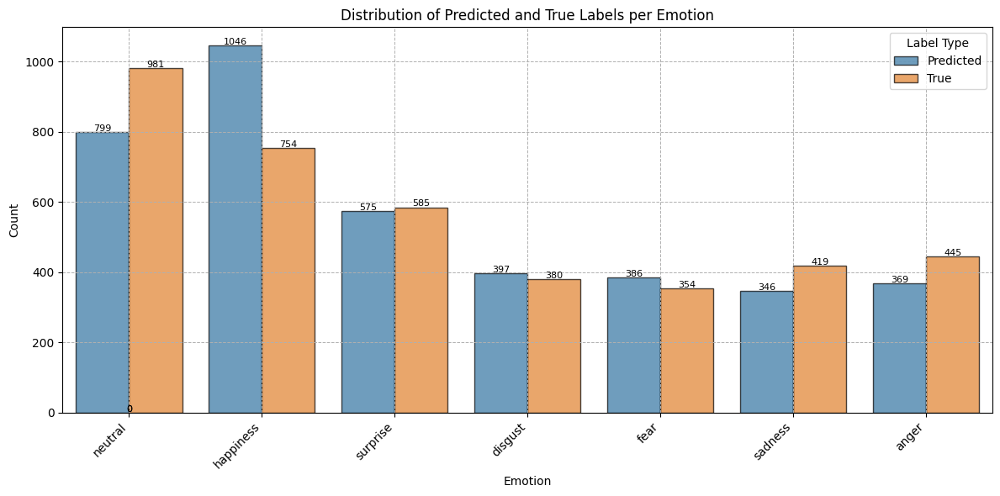

In [57]:
# Create lists of readable labels
predicted_labels_named = [label_names[i] for i in predicted_labels]
true_labels_named = [label_names[i] for i in true_labels]

# Create a DataFrame for plotting
df_plot = pd.DataFrame({
    'Emotion': predicted_labels_named + true_labels_named,
    'Type': ['Predicted'] * len(predicted_labels_named) + ['True'] * len(true_labels_named)
})

plt.figure(figsize=(12, 6))
ax = sns.countplot(data=df_plot, x='Emotion', hue='Type', alpha=0.7, edgecolor='black', linewidth=1)
plt.title("Distribution of Predicted and True Labels per Emotion")
plt.ylabel("Count")
plt.xlabel("Emotion")
plt.xticks(rotation=45, ha='right')
plt.legend(title='Label Type')
plt.tight_layout()

# Add the counts on top of the bars
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x() + p.get_width() / 2., height + 3,
            f'{int(height)}',
            
            ha="center", fontsize=8)
plt.grid(True, linestyle='--', linewidth=0.7)
plt.show()